# Will this employee recommend the employer? — Glassdoor reviews, TF-IDF vs. text embeddings

**Term project, winter 2026/27** · 4IZ582 (Programming for AI and data science) × 4IZ566 (cross-course team)

| | |
|---|---|
| Team | Bc. Ota Vlna (4IZ582) · Bc. Artem Budnyk (4IZ566) |
| Dataset | [Glassdoor job reviews](https://www.kaggle.com/datasets/davidgauthier/glassdoor-job-reviews) (`glassdoor_reviews.csv`, 838 566 reviews) |
| Task | Binary classification of `recommend` — *v* (recommends) vs. *x* (does not recommend); neutral *o* excluded |
| AI component | **Route B — embedding features**: `qwen3-embedding:4b` vectors of the review text vs. a TF-IDF baseline |

### Contents

| Section | CRISP-DM phase |
|---|---|
| 0 Setup and reproducibility | — |
| 1 Business understanding: question, admissible inputs, leakage by design | Business understanding |
| 2 Data, sampling and the firm table | Data understanding |
| 3 Exploratory analysis | Data understanding |
| 4 Preprocessing in pandas | Data preparation |
| 5 Split by firm, leakage checks | Data preparation |
| 6 Embeddings (AI component) | Data preparation |
| 7 Pipelines, models, tuning | Modelling |
| 8 Threshold and evaluation on the test set | Evaluation |
| 9 AI component: TF-IDF vs. embeddings | Evaluation |
| 10 Conclusions, contributions, use of AI tools | — |

### How to run

1. Python 3.12+ with `numpy pandas scipy scikit-learn matplotlib` (the course stack) and `openai` (only needed if the embedding cache is missing).
2. The notebook runs **offline** from the shipped files `data/glassdoor_sample.csv`, `data/firms.csv` and `data/embeddings_qwen3-embedding-4b.csv.gz`.
3. If `data/raw/glassdoor_reviews.csv` (from Kaggle) is present, the sample is rebuilt from it; if the embedding cache is missing,
   the embeddings are requested from the school LiteLLM proxy with the key from the environment variable `LLM_API_KEY` (a local `.env` file is read, the key is never written into the notebook).
4. *Kernel → Restart Kernel and Run All Cells* — the total run time is printed in the last cell.

## 0 Setup and reproducibility

Only the course stack is used. `openai` is the client for the school LiteLLM proxy (seminar 3) and is imported lazily,
only when embeddings have to be computed. One global seed drives the sample, the split, the folds and the searches.

In [1]:
# pip install numpy pandas scipy scikit-learn matplotlib   # course stack
# pip install openai                                         # client for the school LiteLLM proxy; needed only without the cache
import os, json, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, RandomizedSearchCV,
                                     cross_val_score, cross_val_predict, learning_curve)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

T_START = time.perf_counter()
import warnings   # joblib reports idle parallel workers being recycled; harmless, results are unaffected
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")
SEED = 42
N_SAMPLE = 20_000                      # rows in the stratified sample (section 2)
EMB_DIM = 1024                         # embedding dimensions kept in the cache (section 6)
N_JOBS = 4                             # parallel CV jobs; 4 keeps memory use moderate on jupyter.vse.cz

DATA = Path("data")
RAW_CSV = DATA / "raw" / "glassdoor_reviews.csv"
SAMPLE_CSV = DATA / "glassdoor_sample.csv"
FIRMS_CSV = DATA / "firms.csv"
EMB_CSV = DATA / "embeddings_qwen3-embedding-4b.csv.gz"
EMB_META = DATA / "embeddings_qwen3-embedding-4b.meta.json"

random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"v": "#3b7dd8", "x": "#b0413e"}   # recommends / does not recommend

## 1 Business understanding

### 1.1 The question

A Glassdoor review consists of a free-text part (*headline*, *pros*, *cons*), a few facts about the author
(current or former employee, tenure, job title, location, date) and a block of star ratings and yes/no answers.
One of these answers is **"Would you recommend this company to a friend?"** — the target `recommend`.

**Task:** given what an employee *wrote*, predict whether they recommend the employer.
A model like this is useful wherever text about an employer exists *without* an explicit verdict — exit interviews,
internal surveys with open questions, posts on forums — to estimate the share of employees who would recommend the
employer and to flag the reviews that drive non-recommendation.

### 1.2 Admissible inputs — leakage by design

| Columns | Decision | Reason |
|---|---|---|
| `headline`, `pros`, `cons` | **use** (main signal) | The text is what the deployed model receives. |
| `current` (status + tenure), `date_review`, `job_title`, `location` | **use** (light metadata, derived columns) | Known about the author independently of the verdict. |
| `firm` | **not a feature; used as the group** in the split | We want the model to work for employers it has not seen (section 5). |
| `overall_rating`, six sub-ratings, `ceo_approv`, `outlook` | **excluded** | Filled in on the same form, at the same moment, as `recommend` — they are a restatement of the verdict, not a predictor of it. In the intended use (free text without a verdict) they do not exist. Section 5.3 shows that `overall_rating` alone reaches ROC AUC ≈ 0.93. |

### 1.3 What is a good result?

About 71 % of the clear-cut reviews recommend the employer, so always predicting *v* gives 71 % accuracy:
accuracy is reported, but it is compared with that baseline and complemented by **ROC AUC** (threshold-independent,
insensitive to the 71/29 balance) and **average precision of the minority class *x*** (how well the model ranks the
non-recommending reviews — the class an HR analyst would act on).

## 2 Data and sampling

### 2.1 From 838 566 reviews to a stratified sample of 20 000

The raw file (293 MB) is not shipped; the next cell rebuilds the sample from it when it is present and otherwise
loads the shipped sample. Steps, in this order:

1. **Remove rows by subsetting:** keep `recommend ∈ {v, x}`, i.e. drop the neutral *o* (no opinion).
2. **Treat missing values in the text:** a missing headline becomes an empty string (0.3 % of rows); *pros* and *cons* are never missing.
3. **Remove duplicated reviews** (identical headline + pros + cons). A copy of the same review in the training and the test set would leak.
4. **Stratified sample** of `N_SAMPLE` rows with the class ratio of the full data (`groupby(...).sample(frac=...)`, fixed `random_state`).

At the same time a **firm-level table** is aggregated from all 838 566 reviews with `groupby` (number of reviews and the
first year the firm was reviewed — a proxy for the firm's size and visibility). It contains **no target information**
and is joined to the reviews in section 4.

In [2]:
if RAW_CSV.exists():
    raw = pd.read_csv(RAW_CSV)
    raw["review_id"] = np.arange(len(raw))                     # stable row id = position in the original file
    print(f"raw file: {raw.shape[0]:,} rows x {raw.shape[1] - 1} columns")

    # firm-level table: aggregated from ALL reviews, features only (no target)
    firms = (raw.assign(year=pd.to_datetime(raw["date_review"]).dt.year)
                .groupby("firm")
                .agg(firm_n_reviews=("review_id", "size"), firm_first_year=("year", "min"))
                .reset_index())

    clear = raw[raw["recommend"].isin(["v", "x"])].copy()                       # 1) drop neutral 'o'
    for c in ["headline", "pros", "cons"]:
        clear[c] = clear[c].fillna("").str.strip()                              # 2) missing text -> ""
    dedup = clear.drop_duplicates(subset=["headline", "pros", "cons"])          # 3) duplicated reviews
    sample = (dedup.groupby("recommend", group_keys=False)                      # 4) stratified sample
                   .sample(frac=N_SAMPLE / len(dedup), random_state=SEED)
                   .sort_values("review_id").reset_index(drop=True))

    print(f"recommend in {{v, x}} : {len(clear):,} rows  (dropped {len(raw) - len(clear):,} neutral 'o')")
    print(f"after de-duplication: {len(dedup):,} rows  (dropped {len(clear) - len(dedup):,} duplicates)")
    print("class share, full clear-cut data:", dedup["recommend"].value_counts(normalize=True).round(4).to_dict())
    sample.to_csv(SAMPLE_CSV, index=False)
    firms.to_csv(FIRMS_CSV, index=False)
    del raw, clear, dedup
else:
    print("raw file not present - loading the shipped sample")

sample = pd.read_csv(SAMPLE_CSV)
firms = pd.read_csv(FIRMS_CSV)
print(f"sample: {sample.shape[0]:,} rows,  firms table: {firms.shape[0]} firms")
print("class share, sample:", sample["recommend"].value_counts(normalize=True).round(4).to_dict())

raw file: 838,566 rows x 18 columns


recommend in {v, x} : 604,318 rows  (dropped 234,248 neutral 'o')
after de-duplication: 579,565 rows  (dropped 24,753 duplicates)
class share, full clear-cut data: {'v': 0.7081, 'x': 0.2919}


sample: 20,000 rows,  firms table: 428 firms
class share, sample: {'v': 0.708, 'x': 0.292}


The sample keeps the class ratio of the full data to four decimals. 20 000 rows are far more than the
"few thousand" the assignment asks for, yet small enough for the embedding requests (≈ 4 minutes, once) and for the
whole notebook to run within the 30-minute limit. Section 9.2 checks with a learning curve whether more data would help.

## 3 Exploratory analysis

### 3.1 Shape, types and missing values

In [3]:
print(sample.shape)
sample.dtypes.to_frame("dtype").T

(20000, 19)


,firm,date_review,job_title,current,location,overall_rating,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt,recommend,ceo_approv,outlook,headline,pros,cons,review_id
dtype,str,str,str,str,str,int64,float64,float64,float64,float64,float64,float64,str,str,str,str,str,str,int64


In [4]:
missing = sample.isna().mean().mul(100).round(1)
missing[missing > 0].sort_values(ascending=False).to_frame("% missing").T

,diversity_inclusion,location,culture_values,senior_mgmt,comp_benefits,work_life_balance,career_opp,headline
% missing,81.7,28.4,7.9,3.8,3.3,3.2,3.2,0.2


- `diversity_inclusion` is missing for ~80 % of reviews (the question was added to Glassdoor late), `location` for ~28 %, the other ratings for 3–8 %.
  The ratings are excluded anyway (section 1.2); `location` is used only as a *has-location* flag.
- `headline`, `pros` and `cons` were stored as `""` when missing, but `read_csv` turns empty strings back into `NaN` — they are filled again in section 4.
- `job_title` contains a single space for ~8 % of reviews and *Anonymous Employee* for another ~18 %: in effect, missing.

### 3.2 Class balance of the target

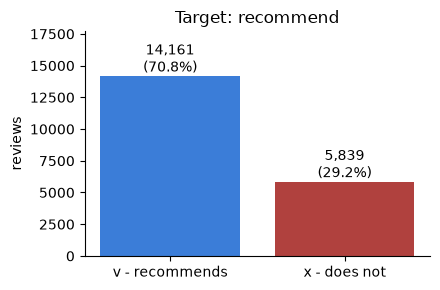

In [5]:
counts = sample["recommend"].value_counts()
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["v - recommends", "x - does not"], counts[["v", "x"]], color=[COLORS["v"], COLORS["x"]])
for i, n in enumerate(counts[["v", "x"]]):
    ax.text(i, n, f"{n:,}\n({n / counts.sum():.1%})", ha="center", va="bottom")
ax.set_ylabel("reviews"); ax.set_ylim(0, counts.max() * 1.25); ax.set_title("Target: recommend")
fig.tight_layout()

71 : 29 — a moderate imbalance. The trivial majority model reaches 71 % accuracy, which is the reference level for
accuracy; ROC AUC and the average precision of class *x* are the primary metrics (section 1.3).

### 3.3 What separates the classes?

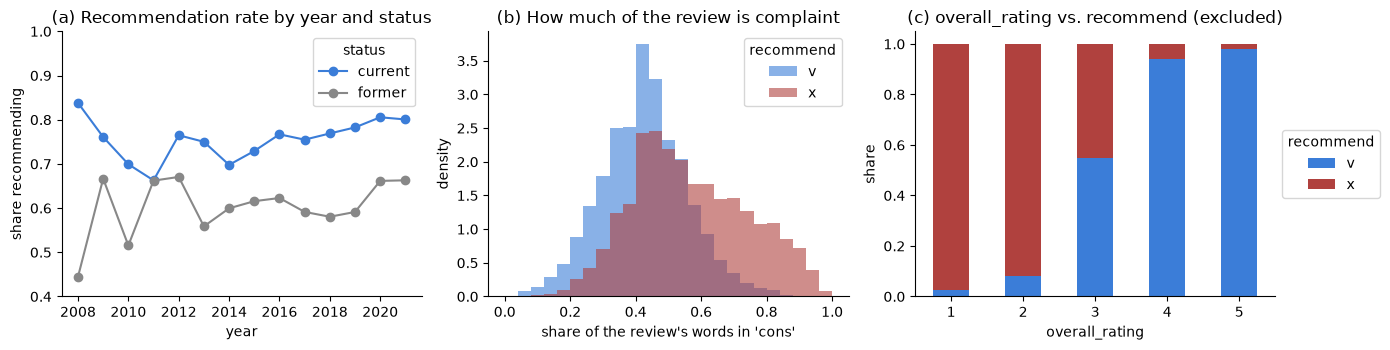

In [6]:
eda = sample.copy()
eda["status"] = np.where(eda["current"].str.startswith("Current"), "current", "former")
eda["year"] = pd.to_datetime(eda["date_review"]).dt.year
eda["words"] = (eda["headline"].fillna("") + " " + eda["pros"].fillna("") + " " + eda["cons"].fillna("")).str.split().str.len()
eda["cons_share"] = eda["cons"].fillna("").str.split().str.len() / eda["words"]
rec = (eda["recommend"] == "v")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

# (a) recommendation rate by status and year
by_year = eda.assign(rec=rec).groupby(["year", "status"])["rec"].mean().unstack()
by_year.plot(ax=axes[0], marker="o", color=["#3b7dd8", "#888888"])
axes[0].set_ylabel("share recommending"); axes[0].set_title("(a) Recommendation rate by year and status")
axes[0].set_ylim(0.4, 1)

# (b) length of the cons relative to the whole review
bins = np.linspace(0, 1, 26)
for cls in ["v", "x"]:
    axes[1].hist(eda.loc[eda["recommend"] == cls, "cons_share"], bins=bins, alpha=.6, density=True,
                 color=COLORS[cls], label=cls)
axes[1].set_xlabel("share of the review's words in 'cons'"); axes[1].set_ylabel("density")
axes[1].set_title("(b) How much of the review is complaint"); axes[1].legend(title="recommend")

# (c) the excluded overall_rating: a near-perfect separator
pd.crosstab(eda["overall_rating"], eda["recommend"], normalize="index")[["v", "x"]].plot.bar(
    stacked=True, ax=axes[2], color=[COLORS["v"], COLORS["x"]], rot=0)
axes[2].set_ylabel("share"); axes[2].set_title("(c) overall_rating vs. recommend (excluded)")
axes[2].legend(title="recommend", loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()

| Plot | Finding | Consequence |
|---|---|---|
| (a) | Current employees recommend more often than former ones (≈ 76 % vs. 62 %) and the share drifts over time. | `is_current`, tenure and `year` are kept as light metadata. |
| (b) | Non-recommenders spend a much larger share of their review on the *cons*. | The text carries the signal; *pros* and *cons* are vectorised separately for TF-IDF. |
| (c) | A 1–2 star review almost never recommends, a 5-star review almost always does. | `overall_rating` is a restatement of the target — excluded (section 1.2, demonstrated in 5.3). |

In [7]:
# a few examples of each class
for cls in ["v", "x"]:
    print(f"===== recommend = {cls}")
    for _, r in sample[sample["recommend"] == cls].sample(2, random_state=SEED).iterrows():
        print(f"[{r['firm']}] {r['headline']}\n  + {str(r['pros'])[:160]}\n  - {str(r['cons'])[:160]}\n")

===== recommend = v
[IBM] Process is nice
  + Helpful, good,nice team, encouraging, communication
  - They allocate work location a.

[Grant-Thornton] The company values employee growth and listens to personal interest of its staff.
  + The company values employee growth and listens to personal interest of its staff.
  - Nothing that I'm aware of

===== recommend = x
[Pearson] Higher Ed Services being run into the ground
  + Benefits are wonderful, most of your colleagues are incredibly smart and talented, flexible work options, good work-life balance, company has great values even 
  - Management is completely out of touch leading to high turnover, there's a lot of hiring of friends and unqualified people, morale is so low and management prete

[Anglian-Water] Customer Service Advisor
  + Good pay and other work incentives
  - Inadequate training and bad management with lots of favoritism in the workplace.



## 4 Preprocessing in pandas

Row-wise derivations below use only the row itself (no statistics learned across rows), so they can run before the
split without leakage. Everything that *is* learned from data — imputation medians, scaling, TF-IDF vocabularies and
IDF weights, SVD components — is fitted inside the `Pipeline` / `ColumnTransformer` in section 7, separately in every fold.

| Operation (assignment checklist) | Where |
|---|---|
| Remove rows by subsetting | Section 2.1 (neutral *o*, duplicates) |
| Treat missing values | Text → `""`; `job_title` blank → *anonymous* flag; unknown tenure → `NaN` imputed in the pipeline + a *tenure stated* flag |
| Derive new columns | Status, tenure in years, review year, word counts, flags, the combined `text` |
| Aggregate with `groupby` | Firm table (section 2.1) |
| Join two tables | Reviews ⋈ firm table on `firm` (many-to-one, validated) |

In [8]:
TENURE_YEARS = {"less than 1 year": 0.5, "more than 1 year": 1, "more than 3 years": 3,
                "more than 5 years": 5, "more than 8 years": 8, "more than 10 years": 10}

def derive_columns(df):
    out = df.copy()
    for c in ["headline", "pros", "cons"]:
        out[c] = out[c].fillna("").astype(str)
    out["job_title"] = out["job_title"].fillna("").str.strip()

    out["is_current"] = out["current"].str.startswith("Current").astype(int)
    tenure = out["current"].str.extract(r",\s*(.+)$")[0]               # e.g. "more than 3 years"
    out["tenure_years"] = tenure.map(TENURE_YEARS)                       # NaN if not stated -> imputed in the pipeline
    out["tenure_stated"] = tenure.notna().astype(int)
    out["year"] = pd.to_datetime(out["date_review"]).dt.year
    out["anonymous_title"] = out["job_title"].isin(["", "Anonymous Employee"]).astype(int)
    out["has_location"] = out["location"].notna().astype(int)
    for c in ["headline", "pros", "cons"]:
        out[f"n_words_{c}"] = out[c].str.split().str.len()
    # one text for the embedding model; the field names tell it which part is praise and which is criticism
    out["text"] = "Headline: " + out["headline"] + "\nPros: " + out["pros"] + "\nCons: " + out["cons"]
    out["y"] = (out["recommend"] == "v").astype(int)                    # 1 = recommends
    return out

df = derive_columns(sample).merge(firms, on="firm", how="left", validate="many_to_one")
assert df["firm_n_reviews"].notna().all() and len(df) == len(sample)

df[["current", "is_current", "tenure_years", "tenure_stated", "year", "anonymous_title",
    "n_words_pros", "n_words_cons", "firm_n_reviews", "y"]].head()

,current,is_current,tenure_years,tenure_stated,year,anonymous_title,n_words_pros,n_words_cons,firm_n_reviews,y
0,"Former Employee, more than 1 year",0,1.0,1,2021,0,15,8,114,1
1,Former Employee,0,NaN,0,2021,0,5,17,114,0
2,"Current Employee, less than 1 year",1,0.5,1,2013,0,68,16,931,1
3,"Former Employee, more than 1 year",0,1.0,1,2015,0,29,79,931,0
4,"Current Employee, less than 1 year",1,0.5,1,2016,0,21,23,931,1


In [9]:
df[["tenure_years", "year", "n_words_headline", "n_words_pros", "n_words_cons", "firm_n_reviews"]].describe().round(1)

,tenure_years,year,n_words_headline,n_words_pros,n_words_cons,firm_n_reviews
count,13544.0,20000.0,20000.0,20000.0,20000.0,20000.0
mean,3.1,2017.4,4.2,16.6,24.1,18596.8
std,2.9,2.9,3.3,20.5,44.5,18554.7
min,0.5,2008.0,0.0,2.0,2.0,6.0
25%,1.0,2016.0,2.0,6.0,7.0,3324.0
50%,3.0,2018.0,3.0,10.0,11.0,9710.0
75%,5.0,2020.0,5.0,20.0,25.0,31941.0
max,10.0,2021.0,26.0,391.0,1126.0,60436.0


Word counts and firm sizes are heavily right-skewed (a firm with 43 748 reviews next to firms with a handful), so the
pipeline takes `log1p` of them before scaling.

### 4.1 Variable roles

In [10]:
TEXT_FIELDS = ["headline", "pros", "cons"]
COUNT_COLS = ["n_words_headline", "n_words_pros", "n_words_cons", "firm_n_reviews"]   # log1p + scale
NUM_COLS = ["tenure_years", "year", "firm_first_year"]                                # impute + scale
BIN_COLS = ["is_current", "tenure_stated", "anonymous_title", "has_location"]          # passthrough
LEAKY_COLS = ["overall_rating", "work_life_balance", "culture_values", "diversity_inclusion",
              "career_opp", "comp_benefits", "senior_mgmt", "ceo_approv", "outlook"]   # excluded (section 1.2)
GROUP_COL = "firm"
TARGET = "y"
META_COLS = COUNT_COLS + NUM_COLS + BIN_COLS
print(len(META_COLS), "metadata features;", len(LEAKY_COLS), "columns excluded as target restatements")

11 metadata features; 9 columns excluded as target restatements


## 5 Train/test split and leakage checks

### 5.1 Split by firm

Reviews of the same firm share vocabulary (the firm's name, its products, its typical complaints) and a firm-specific
recommendation rate (among firms with at least 50 reviews in the sample, from 37 % to 95 %). With a random split the model can partly learn *"reviews mentioning X are
positive"* and the score would describe known employers only. We want a model that works for **employers it has not
seen**, so every firm is entirely in training or entirely in test: `StratifiedGroupKFold` with `groups=firm` keeps
the class ratio while respecting the groups. One of its five folds is the test set (~20 %); the same splitter with
three folds is used for all cross-validation on the training part.

In [11]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(df, df[TARGET], groups=df[GROUP_COL]))
train, test = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
y_train, y_test = train[TARGET].to_numpy(), test[TARGET].to_numpy()
g_train = train[GROUP_COL].to_numpy()

print(f"train: {len(train):,} rows, {train[GROUP_COL].nunique()} firms,  share v = {y_train.mean():.3f}")
print(f"test : {len(test):,} rows, {test[GROUP_COL].nunique()} firms,  share v = {y_test.mean():.3f}")
print("firms in both parts:", len(set(train[GROUP_COL]) & set(test[GROUP_COL])))
print("identical texts in both parts:", len(set(train["text"]) & set(test["text"])))

inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)   # CV on the training part

train: 16,007 rows, 299 firms,  share v = 0.708
test : 3,993 rows, 95 firms,  share v = 0.709
firms in both parts: 0
identical texts in both parts: 0


### 5.2 Temporal leakage

The reviews span 2008–2021. The task is to classify a review that has been written, not to forecast future reviews,
and none of the inputs is recorded after the verdict, so a split by time is not required. The year is a feature and
the firm table uses the whole period (only counts of reviews, no labels), which we accept as a description of the firm.

### 5.3 Demonstration: the excluded ratings

What the excluded columns would do — cross-validated on the training part only, with the same group-aware folds.

In [12]:
def rating_model(cols):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=1000))])

for name, cols in [("overall_rating only", ["overall_rating"]),
                   ("all 7 star ratings", LEAKY_COLS[:7])]:
    auc = cross_val_score(rating_model(cols), train[cols], y_train, groups=g_train, cv=inner, scoring="roc_auc")
    print(f"{name:22s} CV ROC AUC = {auc.mean():.3f}")

overall_rating only    CV ROC AUC = 0.928


all 7 star ratings     CV ROC AUC = 0.953


One column filled in with the verdict reaches an AUC that the text models below do not — it is a restatement of the
target, not a predictor. Including it would make the result look excellent and the model useless for its purpose.

### 5.4 Does the group split matter?

The same TF-IDF + logistic regression model, cross-validated on the training part once with random stratified folds
and once with firm-grouped folds:

In [13]:
quick_tfidf = Pipeline([("tfidf", ColumnTransformer([(f, TfidfVectorizer(min_df=2, sublinear_tf=True), f)
                                                    for f in TEXT_FIELDS])),
                        ("clf", LogisticRegression(C=2.0, max_iter=2000))])
random_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
auc_random = cross_val_score(quick_tfidf, train, y_train, cv=random_cv, scoring="roc_auc")
auc_group = cross_val_score(quick_tfidf, train, y_train, groups=g_train, cv=inner, scoring="roc_auc")
print(f"random folds : ROC AUC {auc_random.mean():.4f} ± {auc_random.std():.4f}")
print(f"firm folds   : ROC AUC {auc_group.mean():.4f} ± {auc_group.std():.4f}")

random folds : ROC AUC 0.8827 ± 0.0058
firm folds   : ROC AUC 0.8849 ± 0.0003


The two estimates are practically equal (the difference is within the fold-to-fold spread): a TF-IDF model of the
review text does not profit measurably from recognising firms. We had expected some optimism from the random folds;
the check shows the concern is small for this data. We keep the grouped protocol anyway, because it is the one that
matches the intended use (employers the model has not seen) and costs nothing.

## 6 AI component: text embeddings

### 6.1 Method

| Choice | Value and reason |
|---|---|
| Model | `qwen3-embedding:4b` on the school LiteLLM proxy (`https://litellm.vse.cz/v1/`, course default, multilingual — some reviews are not in English) |
| Input | `"Headline: …\nPros: …\nCons: …"` — one text per review; the field names keep praise and criticism apart for the model |
| Label | **never** sent to the model — the embedding is a function of the text only, so it can be computed for all rows before the split without leakage |
| Output | 2 560-dimensional vector per review; we keep the first `EMB_DIM = 1024` dimensions and re-normalise them (the model is trained with Matryoshka representation learning, so leading dimensions form a valid shorter embedding; the proxy does not allow requesting fewer dimensions). Section 9.3 compares the dimensions. |
| Cache | `data/embeddings_qwen3-embedding-4b.csv.gz` keyed by `review_id` + a JSON with model, date, number of requests, tokens and time. The notebook only calls the API for reviews missing from the cache. |
| Requests | batches of 64 texts, sequential, retry with exponential backoff and jitter (seminar 3) |

### 6.2 Client and cache

In [14]:
def load_dotenv(path=".env"):
    # minimal .env reader: the key stays in the environment, never in the notebook (no extra package)
    p = Path(path)
    if p.exists():
        for line in p.read_text().splitlines():
            if "=" in line and not line.lstrip().startswith("#"):
                k, v = line.split("=", 1)
                os.environ.setdefault(k.strip(), v.strip().strip("'\""))

BASE_URL = "https://litellm.vse.cz/v1/"
EMBED_MODEL = os.environ.get("LLM_EMBED_MODEL", "qwen3-embedding:4b")
TRANSIENT = {429, 500, 502, 503, 504}

def with_retry(fn, attempts=6, base=1.0, cap=30.0):
    # retry transient failures with exponential backoff and jitter (seminar 3, section 3)
    for i in range(attempts):
        try:
            return fn()
        except Exception as e:
            transient = getattr(e, "status_code", None) in TRANSIENT or \
                        type(e).__name__ in ("APIConnectionError", "APITimeoutError")
            if not transient or i == attempts - 1:
                raise
            time.sleep(min(cap, base * 2 ** i * (0.5 + random.random())))

def l2_normalise(M, eps=1e-12):
    M = np.asarray(M, dtype=np.float32)
    return M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), eps)

def embed_api(texts, batch=64):
    # returns (vectors truncated to EMB_DIM and re-normalised, usage statistics)
    from openai import OpenAI
    load_dotenv()
    client = OpenAI(base_url=BASE_URL, api_key=os.environ["LLM_API_KEY"], timeout=120.0, max_retries=0)
    out, stats, t0 = [], {"requests": 0, "prompt_tokens": 0}, time.perf_counter()
    for i in range(0, len(texts), batch):
        resp = with_retry(lambda: client.embeddings.create(model=EMBED_MODEL, input=texts[i:i + batch]))
        stats["requests"] += 1; stats["prompt_tokens"] += resp.usage.prompt_tokens
        out.append(np.array([d.embedding for d in resp.data], dtype=np.float32))
    stats["seconds"] = round(time.perf_counter() - t0, 1)
    full = np.vstack(out)
    stats["full_dim"] = int(full.shape[1])
    return l2_normalise(full[:, :EMB_DIM]), stats

def get_embeddings(frame):
    # cached embeddings for frame['review_id']; the API is called only for ids missing from the cache
    emb_cols = [f"e{j}" for j in range(EMB_DIM)]
    cache = pd.read_csv(EMB_CSV) if EMB_CSV.exists() else pd.DataFrame(columns=["review_id"] + emb_cols)
    todo = frame.loc[~frame["review_id"].isin(cache["review_id"]), ["review_id", "text"]]
    if len(todo):
        print(f"requesting {len(todo):,} embeddings from {BASE_URL} ({EMBED_MODEL}) ...")
        vecs, stats = embed_api(todo["text"].tolist())
        new = pd.concat([todo[["review_id"]].reset_index(drop=True),
                         pd.DataFrame(vecs.round(5), columns=emb_cols)], axis=1)
        cache = pd.concat([cache, new], ignore_index=True)
        cache.to_csv(EMB_CSV, index=False, compression="gzip")
        stats.update(model=EMBED_MODEL, rows=len(todo), kept_dim=EMB_DIM, date=time.strftime("%Y-%m-%d"))
        EMB_META.write_text(json.dumps(stats, indent=2))
    else:
        print(f"all {len(frame):,} embeddings loaded from the cache {EMB_CSV}")
    E = frame[["review_id"]].merge(cache, on="review_id", how="left", validate="one_to_one")
    return E[emb_cols].to_numpy(dtype=np.float32)

t0 = time.perf_counter()
E_all = get_embeddings(df)
EMB_COLS = [f"e{j}" for j in range(EMB_DIM)]
df_emb = pd.DataFrame(E_all, columns=EMB_COLS)
train = pd.concat([train, df_emb.iloc[train_idx].reset_index(drop=True)], axis=1)
test = pd.concat([test, df_emb.iloc[test_idx].reset_index(drop=True)], axis=1)
print(f"embedding matrix {E_all.shape}, loaded in {time.perf_counter() - t0:.1f} s, NaN: {np.isnan(E_all).sum()}")
print("cost of the cache:", json.loads(EMB_META.read_text()))

all 20,000 embeddings loaded from the cache data/embeddings_qwen3-embedding-4b.csv.gz
embedding matrix (20000, 1024), loaded in 0.5 s, NaN: 0
cost of the cache: {'requests': 313, 'prompt_tokens': 1268926, 'seconds': 228.0, 'full_dim': 2560, 'model': 'qwen3-embedding:4b', 'rows': 20000, 'kept_dim': 1024, 'date': '2026-11-08'}


### 6.3 Sanity check: do the embeddings know which reviews are alike?

Before using the vectors as features (seminar 3, section 4.4): the cosine similarity between reviews of the same
class should be higher on average than between reviews of different classes, and a review's nearest neighbours
should read alike.

In [15]:
rng = np.random.default_rng(SEED)
probe = rng.choice(len(train), 2000, replace=False)
P, yp = train.loc[probe, EMB_COLS].to_numpy(), y_train[probe]
S = l2_normalise(P) @ l2_normalise(P).T
same = (yp[:, None] == yp[None, :]) & ~np.eye(len(yp), dtype=bool)
print(f"mean cosine similarity  same class: {S[same].mean():.3f}   different class: {S[~same & ~np.eye(len(yp), dtype=bool)].mean():.3f}")

q = 0
nn = np.argsort(-S[q])[1:4]
print("\nquery  :", train.loc[probe[q], "text"].replace("\n", " | ")[:200])
for j in nn:
    print(f"{S[q, j]:.3f}  :", train.loc[probe[j], "text"].replace("\n", " | ")[:200])

mean cosine similarity  same class: 0.590   different class: 0.567

query  : Headline: Sr. Analyst | Pros: Employee Friendly Organization | Emphasizes on maintaining work life balance | Cons: Instead of investing in existing experienced workforce hiring new ones externally on 
0.746  : Headline: Great company, better people | Pros: Warm, welcoming mentors willing to invest in the development of younger people | Cons: Work life balance, despite legitimate efforts by senior folks
0.744  : Headline: Great company | Pros: Employee friendly, good work life balance | Cons: None that we can think of
0.743  : Headline: Senior Analyst | Pros: Great compensation and benefit package | Cons: highly stressful and interferes with work/life balance


Reviews of the same class are only slightly more similar on average (≈ 0.59 vs. ≈ 0.57): an embedding encodes the
*topic* of a review (pay, management, work-life balance) at least as strongly as its *verdict*. The nearest neighbours
confirm this — they talk about the same things, with mixed verdicts. The verdict is therefore not a single direction
that cosine similarity picks up; a classifier has to find it, which is what section 7 does.

## 7 Modelling

### 7.1 Design

Two **representations** of the text × two **algorithm families**, each with the same metadata block, each a single
`Pipeline` whose preprocessing is refitted in every fold:

| | Logistic regression (linear) | Histogram gradient boosting (trees) |
|---|---|---|
| **TF-IDF** (baseline) | one TF-IDF per field (headline, pros, cons), word 1–2-grams, sparse | TF-IDF → `TruncatedSVD` (200 components): boosting needs a dense, compact input |
| **Embeddings** (AI component) | 1 024 standardised dimensions | 1 024 dimensions |

plus a **hybrid** (TF-IDF + embeddings, logistic regression) to see whether the two representations are complementary,
and the majority-class **baseline**.

Metadata block (`ColumnTransformer`): `log1p` + scaling of counts, median imputation + scaling of tenure and years,
binary flags passed through.

Separate TF-IDF vectorisers for *pros* and *cons* matter: "management" in *pros* and in *cons* means opposite things,
and a single vectoriser over the concatenated text could not tell them apart.

In [16]:
log_scale = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                      ("scale", StandardScaler())])
impute_scale = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
META = [("counts", log_scale, COUNT_COLS), ("num", impute_scale, NUM_COLS), ("bin", "passthrough", BIN_COLS)]

def tfidf_fields(ngram=(1, 2), min_df=2):
    return [(f, TfidfVectorizer(ngram_range=ngram, min_df=min_df, sublinear_tf=True, strip_accents="unicode"), f)
            for f in TEXT_FIELDS]

def make_pipe(representation, family):
    if representation == "tfidf" and family == "logreg":
        prep = ColumnTransformer(tfidf_fields() + META)
    elif representation == "tfidf" and family == "hgb":
        text = Pipeline([("tfidf", ColumnTransformer(tfidf_fields())),
                         ("svd", TruncatedSVD(n_components=200, random_state=SEED))])
        prep = ColumnTransformer([("text", text, TEXT_FIELDS)] + META)
    elif representation == "emb":
        prep = ColumnTransformer([("emb", StandardScaler(), EMB_COLS)] + META)
    elif representation == "hybrid":
        prep = ColumnTransformer(tfidf_fields() + [("emb", StandardScaler(), EMB_COLS)] + META)
    clf = (LogisticRegression(max_iter=3000, random_state=SEED) if family == "logreg" else
           HistGradientBoostingClassifier(max_iter=400, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=20, random_state=SEED))
    return Pipeline([("prep", prep), ("clf", clf)])

make_pipe("tfidf", "logreg")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('headline', ...), ('pros', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If th

### 7.2 Hyperparameter tuning

`RandomizedSearchCV` with `refit=True`, scoring ROC AUC, on the training part only, with the firm-grouped 3-fold
`inner` splitter (the groups are passed to `fit`). The search spaces are kept small enough for the 30-minute limit:

| Model | Searched | Fixed (and why) |
|---|---|---|
| TF-IDF + LR | `C` (log-uniform 0.05–20), n-gram range and `min_df` of *pros* and *cons* | `sublinear_tf` (dampens repeated words) |
| TF-IDF/SVD + HGB | learning rate, `max_leaf_nodes`, `min_samples_leaf`, L2 penalty | 200 SVD components, early stopping (number of trees chosen on a 10 % validation part of each training fold) |
| Embeddings + LR | `C` (log-uniform 1e-3–1) | — |
| Embeddings + HGB | as for TF-IDF/SVD + HGB | early stopping |
| Hybrid LR | `C` | TF-IDF settings at their defaults |

`best_score_` is the score that *won* the comparison and is optimistic (seminar 2, section 6.7); the number that is
reported is the test score in section 8, computed once.

In [17]:
HGB_SPACE = {"clf__learning_rate": loguniform(0.03, 0.3), "clf__max_leaf_nodes": randint(8, 48),
             "clf__min_samples_leaf": randint(20, 200), "clf__l2_regularization": loguniform(1e-3, 10)}
SPACES = {
    ("tfidf", "logreg"): ({"clf__C": loguniform(0.05, 20),
                           "prep__pros__ngram_range": [(1, 1), (1, 2)], "prep__cons__ngram_range": [(1, 1), (1, 2)],
                           "prep__pros__min_df": [1, 2, 5], "prep__cons__min_df": [1, 2, 5]}, 15),
    ("tfidf", "hgb"): (HGB_SPACE, 10),
    ("emb", "logreg"): ({"clf__C": loguniform(1e-3, 1)}, 10),
    ("emb", "hgb"): (HGB_SPACE, 10),
    ("hybrid", "logreg"): ({"clf__C": loguniform(0.01, 2)}, 8),
}
NAMES = {("tfidf", "logreg"): "TF-IDF + LogReg", ("tfidf", "hgb"): "TF-IDF/SVD + HGB",
         ("emb", "logreg"): "Embeddings + LogReg", ("emb", "hgb"): "Embeddings + HGB",
         ("hybrid", "logreg"): "Hybrid (TF-IDF + emb) + LogReg"}

searches, search_log = {}, []
for key, (space, n_iter) in SPACES.items():
    t0 = time.perf_counter()
    s = RandomizedSearchCV(make_pipe(*key), space, n_iter=n_iter, scoring="roc_auc", cv=inner, refit=True,
                           random_state=SEED, n_jobs=N_JOBS)
    s.fit(train, y_train, groups=g_train)
    searches[NAMES[key]] = s
    params = {k.replace("clf__", "").replace("prep__", ""): (round(float(v), 4) if isinstance(v, float) else v)
              for k, v in s.best_params_.items()}
    search_log.append({"model": NAMES[key], "configs tried": n_iter, "CV ROC AUC (selection)": round(s.best_score_, 4),
                       "std over folds": round(s.cv_results_["std_test_score"][s.best_index_], 4),
                       "best parameters": params, "minutes": round((time.perf_counter() - t0) / 60, 1)})
    print(f"{NAMES[key]:32s} CV AUC {s.best_score_:.4f}   {params}   ({search_log[-1]['minutes']} min)")

pd.DataFrame(search_log).set_index("model")

TF-IDF + LogReg                  CV AUC 0.8979   {'C': 0.5488, 'cons__min_df': 5, 'cons__ngram_range': (1, 2), 'pros__min_df': 2, 'pros__ngram_range': (1, 1)}   (0.2 min)


TF-IDF/SVD + HGB                 CV AUC 0.8803   {'l2_regularization': 0.0042, 'learning_rate': 0.043, 'max_leaf_nodes': 18, 'min_samples_leaf': 107}   (0.6 min)


Embeddings + LogReg              CV AUC 0.9113   {'C': 0.0015}   (0.1 min)


Embeddings + HGB                 CV AUC 0.8973   {'l2_regularization': 0.0398, 'learning_rate': 0.0334, 'max_leaf_nodes': 23, 'min_samples_leaf': 34}   (0.9 min)


Hybrid (TF-IDF + emb) + LogReg   CV AUC 0.9071   {'C': 0.0136}   (0.5 min)


,configs tried,CV ROC AUC (selection),std over folds,best parameters,minutes
model,,,,,
TF-IDF + LogReg,15,0.8979,0.0024,"{'C': 0.5488, 'cons__min_df': 5, 'cons__ngram_range': (1, 2), 'pros__min_df': 2, 'pros__ngram_range': (1, 1)}",0.2
TF-IDF/SVD + HGB,10,0.8803,0.0014,"{'l2_regularization': 0.0042, 'learning_rate': 0.043, 'max_leaf_nodes': 18, 'min_samples_leaf': 107}",0.6
Embeddings + LogReg,10,0.9113,0.0029,{'C': 0.0015},0.1
Embeddings + HGB,10,0.8973,0.0046,"{'l2_regularization': 0.0398, 'learning_rate': 0.0334, 'max_leaf_nodes': 23, 'min_samples_leaf': 34}",0.9
Hybrid (TF-IDF + emb) + LogReg,8,0.9071,0.0027,{'C': 0.0136},0.5


In [18]:
# the full table of configurations tried, per model family (documented, as the assignment asks)
tried = []
for name, s in searches.items():
    r = pd.DataFrame(s.cv_results_)
    r["model"] = name
    r["params"] = r["params"].map(lambda p: {k.split("__")[-1] if k.startswith("clf") else k.replace("prep__", ""):
                                             (round(float(v), 4) if isinstance(v, float) else v) for k, v in p.items()})
    tried.append(r[["model", "params", "mean_test_score", "std_test_score", "rank_test_score"]])
tried = pd.concat(tried).round(4)
tried.sort_values(["model", "rank_test_score"]).groupby("model").head(3)

,model,params,mean_test_score,std_test_score,rank_test_score
6,Embeddings + HGB,"{'l2_regularization': 0.0398, 'learning_rate': 0.0334, 'max_leaf_nodes': 23, 'min_samples_leaf': 34}",0.8973,0.0046,1
1,Embeddings + HGB,"{'l2_regularization': 0.0042, 'learning_rate': 0.043, 'max_leaf_nodes': 18, 'min_samples_leaf': 107}",0.8973,0.0046,2
8,Embeddings + HGB,"{'l2_regularization': 0.5263, 'learning_rate': 0.0846, 'max_leaf_nodes': 25, 'min_samples_leaf': 151}",0.8966,0.0052,3
6,Embeddings + LogReg,{'C': 0.0015},0.9113,0.0029,1
4,Embeddings + LogReg,{'C': 0.0029},0.9110,0.0029,2
5,Embeddings + LogReg,{'C': 0.0029},0.9110,0.0029,3
6,Hybrid (TF-IDF + emb) + LogReg,{'C': 0.0136},0.9071,0.0027,1
5,Hybrid (TF-IDF + emb) + LogReg,{'C': 0.0229},0.9051,0.0028,2
4,Hybrid (TF-IDF + emb) + LogReg,{'C': 0.0229},0.9051,0.0028,3
6,TF-IDF + LogReg,"{'C': 0.5488, 'cons__min_df': 5, 'cons__ngram_range': (1, 2), 'pros__min_df': 2, 'pros__ngram_range': (1, 1)}",0.8979,0.0024,1


### 7.3 Model selection

The final model is the one with the highest **cross-validated** AUC on the training part — chosen before the test set
is touched. The baseline is fitted for reference.

In [19]:
cv_scores = pd.Series({m: s.best_score_ for m, s in searches.items()}).sort_values(ascending=False)
FINAL = cv_scores.index[0]
final_model = searches[FINAL].best_estimator_
baseline = DummyClassifier(strategy="most_frequent").fit(train, y_train)
print("selected by CV:", FINAL, f"(CV AUC {cv_scores.iloc[0]:.4f})")

selected by CV: Embeddings + LogReg (CV AUC 0.9113)


## 8 Evaluation

### 8.1 Decision threshold

`predict` uses 0.5, which is not a deliberate choice. Two errors are possible:

- **false positive** — the model says *recommends* for a review that does not (a dissatisfied employee is missed),
- **false negative** — the model says *does not recommend* for a satisfied one (a false alarm).

For an HR analyst the missed dissatisfied employee is the more costly error, and the classes are imbalanced (29 % *x*).
We weight each error by the inverse frequency of its true class, i.e. a missed *x* costs 0.71 / 0.29 ≈ 2.4 times a
false alarm. Minimising this cost is the same as maximising **balanced accuracy** (the mean of the two recalls).
As in seminar 2, section 6.4, the threshold is chosen on **out-of-fold** predictions for the training part (every row
scored by a model that did not see it, folds grouped by firm) and then applied unchanged to the test set.

out-of-fold AUC 0.9113;  threshold maximising balanced accuracy: 0.697


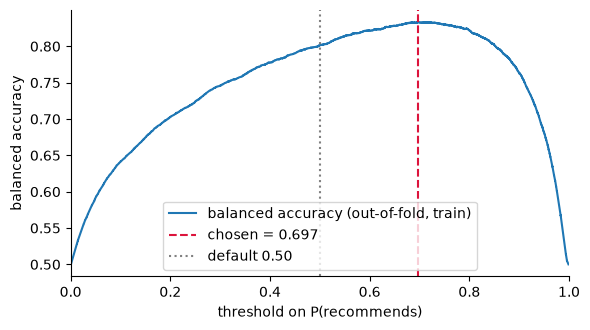

In [20]:
oof = cross_val_predict(final_model, train, y_train, groups=g_train, cv=inner, method="predict_proba", n_jobs=N_JOBS)[:, 1]
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof)
bal_o = (tpr_o + (1 - fpr_o)) / 2                       # balanced accuracy at every distinct threshold
t_star = float(thr_o[np.argmax(bal_o)])
print(f"out-of-fold AUC {roc_auc_score(y_train, oof):.4f};  threshold maximising balanced accuracy: {t_star:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(thr_o[1:], bal_o[1:], label="balanced accuracy (out-of-fold, train)")
ax.axvline(t_star, c="crimson", ls="--", label=f"chosen = {t_star:.3f}")
ax.axvline(0.5, c="grey", ls=":", label="default 0.50")
ax.set_xlim(0, 1); ax.set_xlabel("threshold on P(recommends)"); ax.set_ylabel("balanced accuracy"); ax.legend()
fig.tight_layout()

The chosen threshold lies above 0.5: the model must be more confident before it labels a review *recommends*, which
moves borderline reviews to *does not recommend*. The curve is flat around its maximum, so the exact value is not critical.

### 8.2 The test set — used once

In [21]:
def evaluate(model, X, y, threshold=0.5):
    p = model.predict_proba(X)[:, 1]
    pred = (p >= threshold).astype(int)
    return {"accuracy": accuracy_score(y, pred), "balanced accuracy": balanced_accuracy_score(y, pred),
            "ROC AUC": roc_auc_score(y, p), "AP (class x)": average_precision_score(1 - y, 1 - p)}, p

results, test_proba = {}, {}
results["Baseline (majority class)"], test_proba["Baseline (majority class)"] = evaluate(baseline, test, y_test)
for name, s in searches.items():
    results[name], test_proba[name] = evaluate(s.best_estimator_, test, y_test)       # default threshold 0.5
res = pd.DataFrame(results).T
res.insert(0, "CV ROC AUC (selection)", pd.Series({m: s.best_score_ for m, s in searches.items()}))
res.round(4).sort_values("ROC AUC", ascending=False)

,CV ROC AUC (selection),accuracy,balanced accuracy,ROC AUC,AP (class x)
Embeddings + LogReg,0.9113,0.8507,0.8002,0.9056,0.8270
Hybrid (TF-IDF + emb) + LogReg,0.9071,0.8462,0.8011,0.9009,0.8185
TF-IDF + LogReg,0.8979,0.8370,0.7690,0.8944,0.8018
Embeddings + HGB,0.8973,0.8465,0.7808,0.8907,0.8083
TF-IDF/SVD + HGB,0.8803,0.8187,0.7480,0.8793,0.7725
Baseline (majority class),NaN,0.7087,0.5000,0.5000,0.2913


Accuracy and balanced accuracy in this table are at the default threshold 0.5, the threshold-independent ROC AUC and
AP are the comparison of the representations. Random ranking would give AP (class *x*) = 0.29, the prevalence of *x*.
The CV scores and the test scores agree closely: the grouped cross-validation was a faithful estimate.

### 8.3 The selected model at the chosen threshold

Embeddings + LogReg at threshold 0.697: {'accuracy': 0.8317, 'balanced accuracy': 0.8253, 'ROC AUC': 0.9056, 'AP (class x)': 0.827}
                        precision    recall  f1-score   support

x - does not recommend      0.676     0.810     0.737      1163
        v - recommends      0.915     0.841     0.876      2830

              accuracy                          0.832      3993
             macro avg      0.796     0.825     0.807      3993
          weighted avg      0.845     0.832     0.836      3993



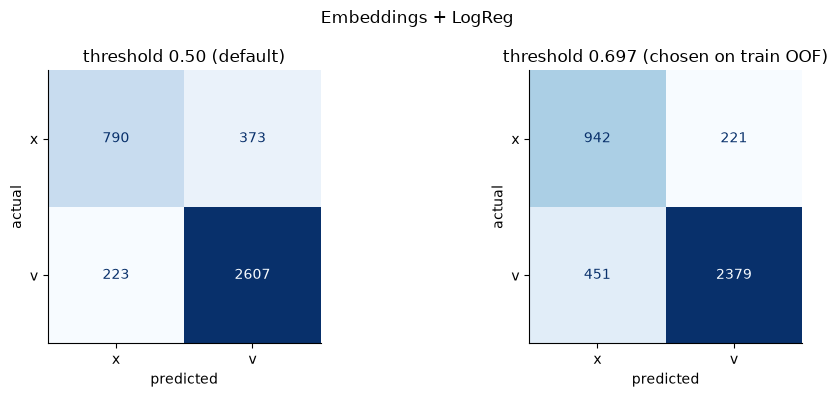

In [22]:
final_metrics, p_final = evaluate(final_model, test, y_test, threshold=t_star)
pred_final = (p_final >= t_star).astype(int)
print(f"{FINAL} at threshold {t_star:.3f}:", {k: round(v, 4) for k, v in final_metrics.items()})
print(classification_report(y_test, pred_final, target_names=["x - does not recommend", "v - recommends"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (p_final >= 0.5).astype(int), display_labels=["x", "v"],
                                        ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("threshold 0.50 (default)")
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["x", "v"],
                                        ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title(f"threshold {t_star:.3f} (chosen on train OOF)")
for ax in axes: ax.set_xlabel("predicted"); ax.set_ylabel("actual")
fig.suptitle(FINAL); fig.tight_layout()

At the chosen threshold the model finds a larger share of the non-recommending reviews (recall of *x*) at the price of
more false alarms — the trade-off chosen in 8.1. Accuracy drops slightly below the 0.5-threshold value; that is expected,
accuracy rewards the majority class.

### 8.4 ROC and precision–recall curves of all models

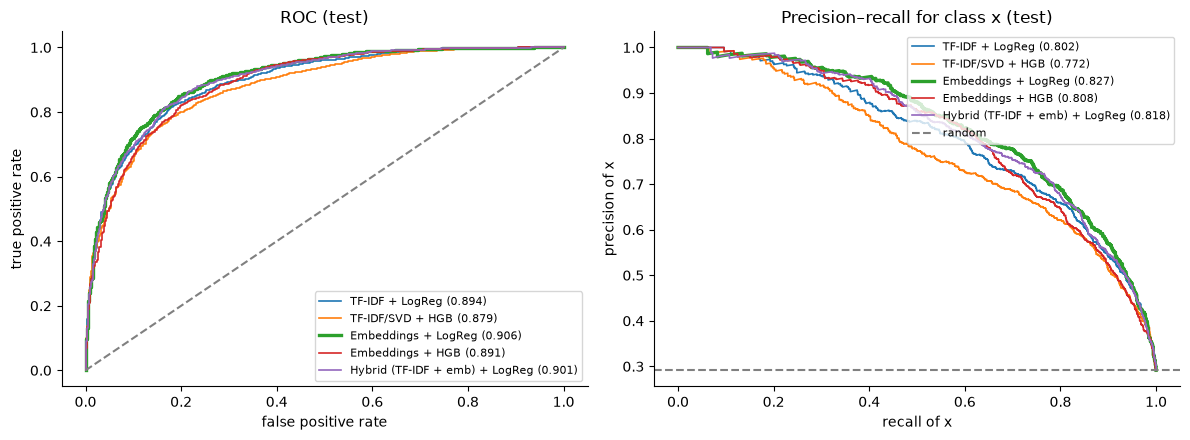

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in test_proba.items():
    if name.startswith("Baseline"):
        continue
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(1 - y_test, 1 - p)
    lw = 2.4 if name == FINAL else 1.2
    axes[0].plot(fpr, tpr, lw=lw, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, lw=lw, label=f"{name} ({average_precision_score(1 - y_test, 1 - p):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", c="grey"); axes[0].set_title("ROC (test)")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[1].axhline((1 - y_test).mean(), ls="--", c="grey", label="random")
axes[1].set_title("Precision–recall for class x (test)"); axes[1].set_xlabel("recall of x"); axes[1].set_ylabel("precision of x")
for ax in axes: ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
fig.tight_layout()

## 9 AI component: TF-IDF vs. embeddings

### 9.1 Head-to-head on the test set

Same split, same metadata, same tuning protocol — only the representation of the text differs.

In [24]:
pairs = [("LogReg", "TF-IDF + LogReg", "Embeddings + LogReg"), ("HGB", "TF-IDF/SVD + HGB", "Embeddings + HGB")]
rows = []
for fam, a, b in pairs:
    for metric in ["ROC AUC", "AP (class x)"]:
        rows.append({"family": fam, "metric": metric, "TF-IDF": res.loc[a, metric], "embeddings": res.loc[b, metric],
                     "difference": res.loc[b, metric] - res.loc[a, metric]})
head2head = pd.DataFrame(rows).round(4)

# bootstrap of the test set: how certain is the difference for logistic regression?
rng = np.random.default_rng(SEED)
pa, pb = test_proba["TF-IDF + LogReg"], test_proba["Embeddings + LogReg"]
diffs = []
for _ in range(500):
    i = rng.integers(0, len(y_test), len(y_test))
    diffs.append(roc_auc_score(y_test[i], pb[i]) - roc_auc_score(y_test[i], pa[i]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"LogReg: AUC(embeddings) - AUC(TF-IDF) = {np.mean(diffs):+.4f}, 95 % bootstrap interval [{lo:+.4f}, {hi:+.4f}]")
head2head

LogReg: AUC(embeddings) - AUC(TF-IDF) = +0.0114, 95 % bootstrap interval [+0.0036, +0.0187]


,family,metric,TF-IDF,embeddings,difference
0,LogReg,ROC AUC,0.8944,0.9056,0.0112
1,LogReg,AP (class x),0.8018,0.8270,0.0252
2,HGB,ROC AUC,0.8793,0.8907,0.0114
3,HGB,AP (class x),0.7725,0.8083,0.0359


The bootstrap resamples test reviews (not firms), so the interval is somewhat too narrow; it shows whether the
difference is larger than the noise of a 4 000-review test set.

### 9.2 Learning curves: how much labelled data does each representation need?

Embeddings bring knowledge from pre-training, TF-IDF learns every word from the labelled data. If that matters, the
gap should be largest with few labelled reviews. Cross-validated on the training part (grouped folds), tuned
hyperparameters fixed.

TF-IDF + LogReg {np.int64(320): np.float64(0.8063), np.int64(855): np.float64(0.843), np.int64(2137): np.float64(0.8704), np.int64(5344): np.float64(0.8885), np.int64(10689): np.float64(0.8979)}


Embeddings + LogReg {np.int64(320): np.float64(0.8683), np.int64(855): np.float64(0.884), np.int64(2137): np.float64(0.8975), np.int64(5344): np.float64(0.9063), np.int64(10689): np.float64(0.9113)}


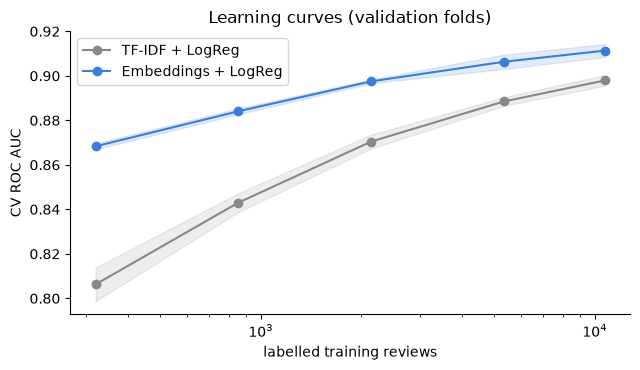

In [25]:
sizes = np.array([0.03, 0.08, 0.2, 0.5, 1.0])
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, colour in [("TF-IDF + LogReg", "#888888"), ("Embeddings + LogReg", "#3b7dd8")]:
    n, _, val = learning_curve(searches[name].best_estimator_, train, y_train, groups=g_train, cv=inner,
                               train_sizes=sizes, scoring="roc_auc", shuffle=True, random_state=SEED, n_jobs=N_JOBS)
    ax.plot(n, val.mean(1), "o-", c=colour, label=name)
    ax.fill_between(n, val.mean(1) - val.std(1), val.mean(1) + val.std(1), color=colour, alpha=.15)
    print(name, dict(zip(n, val.mean(1).round(4))))
ax.set_xscale("log"); ax.set_xlabel("labelled training reviews"); ax.set_ylabel("CV ROC AUC")
ax.set_title("Learning curves (validation folds)"); ax.legend()
fig.tight_layout()

### 9.3 How many embedding dimensions are needed?

Leading dimensions of a Matryoshka-trained embedding, re-normalised, logistic regression with the tuned `C`,
grouped CV on the training part:

In [26]:
C_emb = searches["Embeddings + LogReg"].best_params_["clf__C"]
dim_rows = []
for k in [32, 128, 256, 512, EMB_DIM]:
    Xk = l2_normalise(train[EMB_COLS[:k]].to_numpy())
    m = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=C_emb, max_iter=3000))])
    s = cross_val_score(m, Xk, y_train, groups=g_train, cv=inner, scoring="roc_auc", n_jobs=N_JOBS)
    dim_rows.append({"dimensions": k, "CV ROC AUC (embeddings only)": round(s.mean(), 4)})
pd.DataFrame(dim_rows).set_index("dimensions").T

dimensions,32,128,256,512,1024
CV ROC AUC (embeddings only),0.7968,0.8785,0.8961,0.9062,0.9105


Performance grows up to 512–1 024 dimensions and flattens. During development we also ran the full 2 560-dimensional
vectors with the same protocol (C = 0.01): CV ROC AUC 0.904, i.e. no better than 1 024 dimensions, which is why only
1 024 are cached (48 MB instead of ~120 MB).

### 9.4 Where do the representations disagree?

Test reviews on which the two logistic regressions disagree most — read to understand *what* the embeddings capture.

In [27]:
cmp = test[["text", "recommend"]].assign(p_tfidf=pa.round(3), p_emb=pb.round(3), gap=(pb - pa).round(3))
cmp["text"] = cmp["text"].str.replace("\n", " | ").str.slice(0, 260)
print("embeddings right, TF-IDF wrong (largest gaps):")
right_emb = cmp[((cmp["p_emb"] >= 0.5) == (cmp["recommend"] == "v")) & ((cmp["p_tfidf"] >= 0.5) != (cmp["recommend"] == "v"))]
display(right_emb.reindex(right_emb["gap"].abs().sort_values(ascending=False).index).head(4))
print("TF-IDF right, embeddings wrong (largest gaps):")
right_tfidf = cmp[((cmp["p_tfidf"] >= 0.5) == (cmp["recommend"] == "v")) & ((cmp["p_emb"] >= 0.5) != (cmp["recommend"] == "v"))]
display(right_tfidf.reindex(right_tfidf["gap"].abs().sort_values(ascending=False).index).head(4))
print(f"disagreements at 0.5: {((pa >= 0.5) != (pb >= 0.5)).sum()} of {len(y_test)} test reviews;  "
      f"embeddings right in {len(right_emb)}, TF-IDF right in {len(right_tfidf)}")

embeddings right, TF-IDF wrong (largest gaps):


,text,recommend,p_tfidf,p_emb,gap
1807,Headline: former jaguar employees who were bullied out of there jobs by corrupt supervision and HR staff get togethe...,x,0.934,0.032,-0.901
2431,Headline: Unbalanced work shoved on an over night employee | Pros: Learn to clean a flat top grill for 3 different m...,x,0.821,0.042,-0.780
2084,Headline: Money is money | Pros: Never enough to get buy struggle to get hours with low pay | Cons: Don't Recommend ...,x,0.708,0.012,-0.696
2627,"Headline: Well, it is what it is. | Pros: My management did their best with what they had. If you work hard, you wil...",x,0.801,0.109,-0.692


TF-IDF right, embeddings wrong (largest gaps):


,text,recommend,p_tfidf,p_emb,gap
157,Headline: Review | Pros: Great people to work with! | Cons: Careers dont exist. Annual re-orgs/Layoff's,v,0.914,0.109,-0.805
1731,Headline: Great teams but senior leadership disconnected. | Pros: Great and high profile projects | Cons: Bully cult...,v,0.835,0.146,-0.689
2023,"Headline: Amazing | Pros: Slow, bad customer service itwas nice working night, customers seem nice at night | Cons: ...",v,0.879,0.208,-0.671
1601,"Headline: Pay is too low for non client service professionals | Pros: Good PTO, benefits and learning opps | Cons: P...",v,0.827,0.165,-0.662


disagreements at 0.5: 429 of 3993 test reviews;  embeddings right in 241, TF-IDF right in 186


### 9.5 Cost of the AI component

In [28]:
meta = json.loads(EMB_META.read_text())
rows_full = 604_318 - 24_753          # clear-cut, de-duplicated reviews in the full data (section 2.1)
scale = rows_full / meta["rows"]
print(f"model {meta['model']}, computed {meta['date']}: {meta['rows']:,} reviews in {meta['requests']} requests "
      f"(batches of 64), {meta['prompt_tokens']:,} input tokens, {meta['seconds'] / 60:.1f} min")
print(f"per 1 000 reviews: {1000 * meta['prompt_tokens'] / meta['rows']:,.0f} tokens, "
      f"{1000 * meta['seconds'] / meta['rows']:.1f} s")
print(f"extrapolated to all {rows_full:,} clear-cut reviews: {meta['prompt_tokens'] * scale / 1e6:.1f} M tokens, "
      f"~{meta['seconds'] * scale / 3600:.1f} h of sequential requests")
print("The school proxy reports a price of 0; for orientation, commercial embedding APIs charge roughly "
      "0.02-0.15 USD per million tokens, i.e. well under 1 USD for this sample.")

model qwen3-embedding:4b, computed 2026-11-08: 20,000 reviews in 313 requests (batches of 64), 1,268,926 input tokens, 3.8 min
per 1 000 reviews: 63,446 tokens, 11.4 s
extrapolated to all 579,565 clear-cut reviews: 36.8 M tokens, ~1.8 h of sequential requests
The school proxy reports a price of 0; for orientation, commercial embedding APIs charge roughly 0.02-0.15 USD per million tokens, i.e. well under 1 USD for this sample.


## 10 Conclusions

**Results.** The summary below is computed from the tables above (section 8.2 and 9):

In [29]:
summary = res.loc[[n for n in res.index if not n.startswith("Baseline")], ["CV ROC AUC (selection)", "ROC AUC", "AP (class x)"]]
print(summary.round(4).sort_values("ROC AUC", ascending=False).to_string())
print(f"\nselected model: {FINAL};  test at threshold {t_star:.3f}: " +
      ", ".join(f"{k} {v:.3f}" for k, v in final_metrics.items()))
print(f"baseline accuracy (always 'recommends'): {res.loc['Baseline (majority class)', 'accuracy']:.3f}")

                                CV ROC AUC (selection)  ROC AUC  AP (class x)
Embeddings + LogReg                             0.9113   0.9056        0.8270
Hybrid (TF-IDF + emb) + LogReg                  0.9071   0.9009        0.8185
TF-IDF + LogReg                                 0.8979   0.8944        0.8018
Embeddings + HGB                                0.8973   0.8907        0.8083
TF-IDF/SVD + HGB                                0.8803   0.8793        0.7725

selected model: Embeddings + LogReg;  test at threshold 0.697: accuracy 0.832, balanced accuracy 0.825, ROC AUC 0.906, AP (class x) 0.827
baseline accuracy (always 'recommends'): 0.709


**Interpretation.**

- **The task is learnable from text alone.** Every text model ranks reviews far better than chance; the excluded
  `overall_rating` would do better still, but only because it restates the verdict (section 5.3).
- **Embeddings beat TF-IDF, consistently but modestly.** With logistic regression the test ROC AUC rises from 0.894
  to 0.906 (bootstrap 95 % interval of the difference +0.004 to +0.019) and the average precision of class *x* from
  0.802 to 0.827; with gradient boosting the gain is similar (+0.011 AUC, +0.036 AP). The cross-validated ranking on
  the training part was the same, so the model was selected without looking at the test set.
- **The gain is largest with little labelled data** (9.2): with 320 labelled reviews the embeddings reach CV AUC 0.87
  against 0.81 for TF-IDF; with 10 700 reviews the gap shrinks to about 0.013. Pre-training substitutes for labels — the
  practical argument for embeddings when labelled reviews are scarce.
- **Combining the two does not help.** The hybrid (TF-IDF + embeddings in one logistic regression) lands between the two:
  a single `C` has to regularise tens of thousands of sparse and 1 024 dense columns at once, and the embeddings
  already carry most of what the words do.
- **Linear models are enough.** On both representations logistic regression is better than gradient boosting at a
  fraction of the training time; high-dimensional text features are close to linearly separable.
- **Threshold.** Moving the threshold from 0.5 to about 0.70 (chosen on out-of-fold training predictions) raises the
  recall of the non-recommending class to 0.81 and balanced accuracy from 0.800 to 0.825, at the cost of 2 points of
  accuracy (0.851 → 0.832) — both clearly above the majority baseline of 0.709.
- **Errors** (9.4): TF-IDF is misled when authors write complaints into the *pros* field (any word there pushes the
  score up) or negate a positive word ("Don't Recommend"); the embeddings read the meaning. The embeddings in turn fail
  on short reviews with harsh *cons* whose author still recommends ("Great people … Careers dont exist") — genuinely
  ambiguous cases where the field-aware TF-IDF weighting of *pros* happens to be right.

**Limitations.** One sample of 20 000 reviews and one test fold of firms; the bootstrap interval ignores the
grouping by firm. The embedding model is accessed through an alias that may change; the cache records the date.
Reviews are written to be read by others, so the verdict and the text are not independent — the model is useful for
text *without* a verdict, which we could not test on a separate source.

**Lessons learned.** Most of the work was deciding what the model may see: the ratings, the firm and duplicates would
each have inflated the score without making the model more useful.

## 11 Contributions and use of AI tools

| Member | Contribution |
|---|---|
| Bc. Ota Vlna (4IZ582) | *to be completed by the team* — e.g. AI component (embeddings, cache, comparison), modelling and evaluation |
| Bc. Artem Budnyk (4IZ566) | *to be completed by the team* — e.g. data understanding, sampling, preprocessing, TF-IDF baseline |

**AI tools.** *To be completed by the team, honestly and specifically* — for example: the notebook skeleton and parts
of the code were drafted with an AI coding assistant (Claude Code); every cell was run, checked and edited by the team,
and all modelling decisions (excluded columns, split by firm, threshold rule) were discussed and can be defended by both
members. The embedding model `qwen3-embedding:4b` is part of the analysis itself (section 6).

## References

- D. Gauthier: *Glassdoor Job Reviews*, Kaggle, 2024. https://www.kaggle.com/datasets/davidgauthier/glassdoor-job-reviews
- Qwen Team: *Qwen3 Embedding: Advancing Text Embedding and Reranking Through Foundation Models*, 2025.
- Kapoor, S. et al.: *REFORMS: Reporting standards for ML-based science* / Princeton reproducibility checklist. https://reproducible.cs.princeton.edu/
- Course materials 4IZ566/4IZ582, seminars 1–4 (pipelines and leakage, metrics and thresholds, embeddings and caching).

In [30]:
print(f"total run time: {(time.perf_counter() - T_START) / 60:.1f} min")

total run time: 2.4 min
